# 01 — Exploratory Data Analysis
**Comparative Evaluation of Imbalance-Aware Classification and Anomaly
Detection Methods for Identifying At-Risk Graduates in Imbalanced
Tracer Study Data Using PR-AUC**

Institute of Education Tracer Study, CCSFP (2023-2025 graduates,
n=157). This notebook covers dataset structure, target distribution,
and univariate/bivariate exploration ahead of preprocessing.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src.preprocessing import rename_columns
from src.reporting import save_figure, save_table

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

In [2]:
df = pd.read_excel(PROJECT_ROOT / "data" / "raw" / "tracer_study_raw.xlsx")
df = rename_columns(df)

print(f"Raw shape: {df.shape}")
preview_cols = ["program", "batch", "sex", "birth_year", "study_hours",
                "internship", "working_student", "current_situation"]
display(df[preview_cols].dtypes.to_frame("dtype"))

Raw shape: (157, 197)


,dtype
program,str
batch,int64
sex,str
birth_year,int64
study_hours,str
internship,str
working_student,str
current_situation,str


## Target: employment status

`current_situation` (raw, multi-select) → `employment_status` is derived in preprocessing. Previewing the raw distribution here.

,Count
current_situation,
Employed,126
Unemployed,31


Unemployed (minority/at-risk class): 31 / 157 (19.7%)


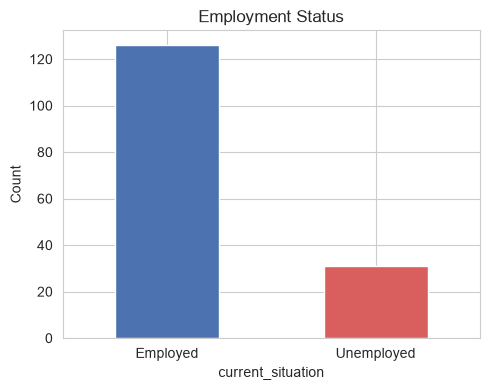

In [3]:
with_work = ["Employment", "Self-employed/freelance work", "Military or other civil service"]
pattern = "|".join(with_work)
employed = df["current_situation"].astype(str).str.contains(pattern, case=False, na=False)

counts = employed.value_counts().rename({True: "Employed", False: "Unemployed"})
display(counts.to_frame("Count"))
save_table(counts.to_frame("Count"), "employment_status")
print(f"Unemployed (minority/at-risk class): {counts['Unemployed']} / {len(df)} "
      f"({counts['Unemployed']/len(df)*100:.1f}%)")

fig, ax = plt.subplots(figsize=(5, 4))
counts.plot(kind="bar", color=["#4c72b0", "#d95f5f"], ax=ax)
ax.set_title("Employment Status")
ax.set_ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
save_figure(fig, "employment_status")
plt.show()

**~80/20 imbalance.** This is the central methodological challenge the thesis addresses: identifying the unemployed minority reliably, not just achieving high aggregate accuracy.

## Demographics

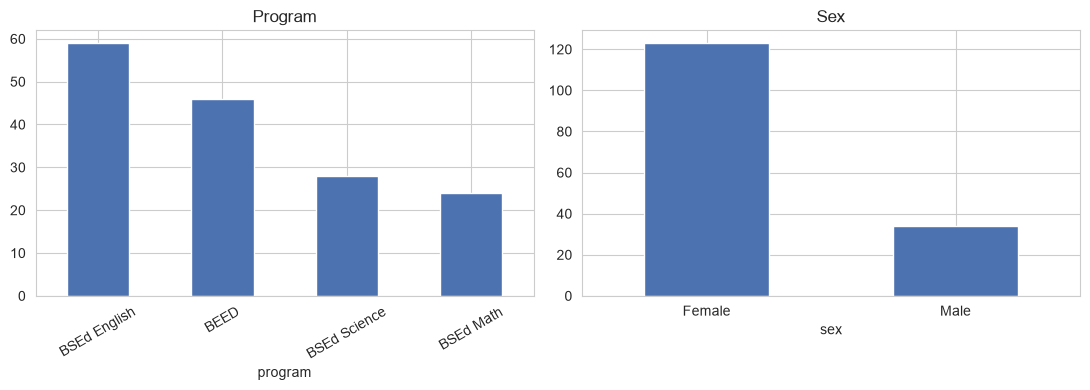

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

df["program"].value_counts().plot(kind="bar", ax=axes[0], color="#4c72b0")
axes[0].set_title("Program")
axes[0].tick_params(axis="x", rotation=30)

df["sex"].value_counts().plot(kind="bar", ax=axes[1], color="#4c72b0")
axes[1].set_title("Sex")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
save_figure(fig, "demographics")
plt.show()

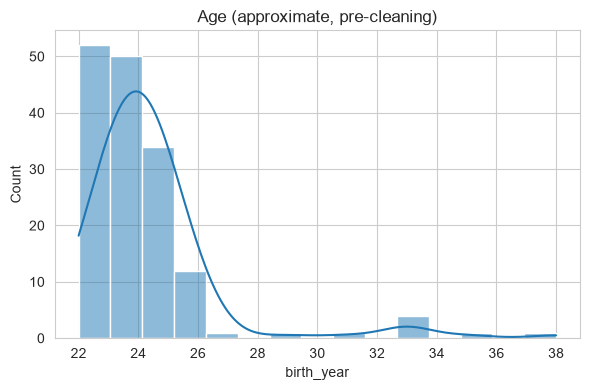

count    157.000000
mean      24.433121
std        2.362294
min       22.000000
25%       23.000000
50%       24.000000
75%       25.000000
max       38.000000
Name: birth_year, dtype: float64


In [5]:
age = 2025 - pd.to_numeric(df["birth_year"], errors="coerce")

fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(age, bins=15, kde=True, ax=ax)
ax.set_title("Age (approximate, pre-cleaning)")
plt.tight_layout()
save_figure(fig, "age_distribution")
plt.show()

print(age.describe())
save_table(age.describe().to_frame("age"), "age_summary_precheck");

A known data-entry error (one respondent's birth year recorded as 2009 instead of 2001, yielding an implausible age of ~14-16) is corrected at the source in `data/raw/tracer_study_raw.xlsx` — confirmed clean in `02_preprocessing.ipynb`'s validation step.

## Internship and study-habit variables

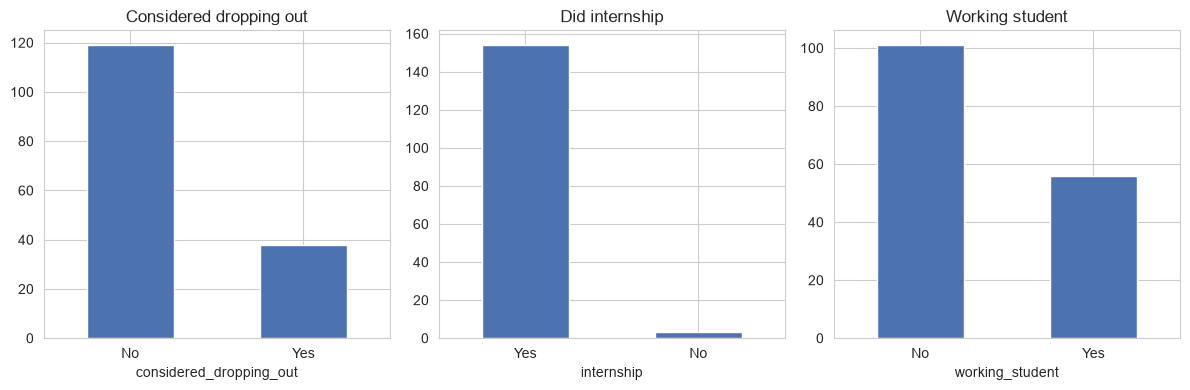

In [6]:
cols = ["considered_dropping_out", "internship", "working_student"]
labels = ["Considered dropping out", "Did internship", "Working student"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col, label in zip(axes, cols, labels):
    df[col].value_counts().plot(kind="bar", ax=ax, color="#4c72b0")
    ax.set_title(label)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
save_figure(fig, "internship_study_habits")
plt.show()

## Key takeaways for preprocessing

- Target imbalance (~80/20) confirms PR-AUC over accuracy/ROC-AUC as the primary metric (per the thesis's evaluation framework).
- A known birth-year data-entry error needs verifying as corrected.
- Categorical/ordinal survey fields (internship counts/durations, study hours) need harmonization before encoding — several raw category labels have typos/casing/numbering inconsistencies, addressed in `02_preprocessing.ipynb`.